**Name:** Danyal Salman Alhashem  
**Student ID:** 2240002713  
**Lab 10:** Introduction to Machine Translation

# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

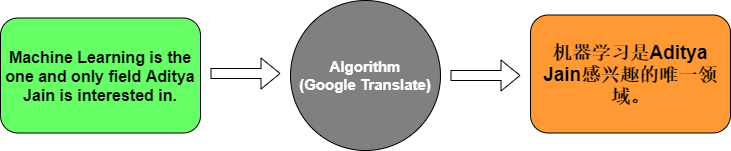

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.0000e+00 - loss: 2.4864 - val_accuracy: 0.0000e+00 - val_loss: 2.4878
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.5714 - loss: 2.4767 - val_accuracy: 0.0000e+00 - val_loss: 2.4898
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.5714 - loss: 2.4667 - val_accuracy: 0.0000e+00 - val_loss: 2.4921
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.5714 - loss: 2.4561 - val_accuracy: 0.0000e+00 - val_loss: 2.4945
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.5714 - loss: 2.4443 - val_accuracy: 0.0000e+00 - val_loss: 2.4972
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.5714 - loss: 2.4310 - val_accuracy: 0.0000e+00 - val_loss: 2.5004
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5714 - loss: 2.4157 - val_accuracy: 0.0000e+00 - val_loss: 2.5039
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5714 - loss: 2.3980 - val_ac

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step
Input: How are you?
Translation: comment va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


### Task 1 – Answers

**1. What does the Embedding layer do to a word index?**  
It turns each word index (an integer such as `4` for "you") into a dense vector of real numbers (here 64 values). The vectors are learned during training, so words that are used in similar ways end up with similar vectors. This gives the network a meaningful numeric representation instead of a meaningless ID.

**2. What is the role of the Encoder LSTM?**  
The encoder LSTM reads the English sentence word by word and keeps updating its internal memory. At the end it outputs one fixed-size vector (the *context vector*) that summarizes the meaning of the whole input sentence. `RepeatVector` then copies this vector once for every position of the French output.

**3. What does the Decoder LSTM do?**  
The decoder LSTM takes the repeated context vector and, with `return_sequences=True`, produces one hidden state for every time step of the output sentence. Each hidden state carries the information needed to generate the French word at that position, so the decoder "unfolds" the summary into a sequence.

**4. Why do we use `softmax` in the final layer?**  
At each time step the `Dense` layer gives one score per word in the French vocabulary. Softmax converts these scores into probabilities that are all positive and sum to 1. This lets us pick the most likely word with `argmax`, and it matches the `sparse_categorical_crossentropy` loss used for training.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

### Task 2 – Solution

**Plan:**
1. Load the English–French dataset from Kaggle (`eng_-french.csv`).
2. Clean the text and keep short sentences so the model can train in reasonable time.
3. Tokenize and pad both languages.
4. Build the same Encoder–Decoder LSTM architecture from the lab (bigger units).
5. Train, evaluate on a test set, and translate sample e-commerce style sentences.

In [8]:
import os, re, string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

tf.random.set_seed(42)
np.random.seed(42)

#### 1. Load the dataset
On Colab the dataset is downloaded with `kagglehub`. If you already downloaded the CSV, put it next to the notebook and it will be used directly.

In [9]:
CSV_NAME = "eng_-french.csv"

if os.path.exists(CSV_NAME):
    csv_path = CSV_NAME
else:
    # !pip install kagglehub
    import kagglehub
    folder = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
    csv_path = os.path.join(folder, CSV_NAME)

df = pd.read_csv(csv_path)
df.columns = ["english", "french"]   # original names: 'English words/sentences', 'French words/sentences'
print(df.shape)
df.head()

(175621, 2)


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


#### 2. Clean the text and select short sentences

In [10]:
def clean(text):
    text = str(text).lower().strip()
    text = text.replace("\u2019", "'").replace("\u202f", " ").replace("\xa0", " ")
    text = re.sub(r"[^\w\s']", " ", text)      # remove punctuation, keep letters (incl. accents) and apostrophes
    text = re.sub(r"\s+", " ", text).strip()
    return text

df = df.dropna().drop_duplicates()
df["english"] = df["english"].apply(clean)
df["french"]  = df["french"].apply(clean)

# Keep sentences up to MAX_WORDS words so training is fast
MAX_WORDS   = 8
NUM_SAMPLES = 30000
df = df[(df["english"].str.split().str.len() <= MAX_WORDS) &
        (df["french"].str.split().str.len()  <= MAX_WORDS)]
df = df.sample(n=min(NUM_SAMPLES, len(df)), random_state=42).reset_index(drop=True)

print("Pairs used:", len(df))
df.head(10)

Pairs used: 30000


,english,french
0,someone is lying,quelqu'un ment
1,i think i could get used to this,je pense que je pourrais m'y habituer
2,i cooked the pasta too long,j'ai fait chauffer les pâtes trop longtemps
3,i knew that that wasn't true,je savais que ce n'était pas vrai
4,i want to talk with you,je veux vous parler
5,you are very rich,vous êtes fort riche
6,i think that's up to you now,je pense que ça dépend désormais de vous
7,where were you last monday,où étiez vous lundi dernier
8,i think it's awesome,je pense que c'est génial
9,what are you going to do with it,que vas tu en faire


#### 3. Tokenize and pad

In [11]:
tok_eng = Tokenizer(filters="")   # text is already cleaned
tok_frn = Tokenizer(filters="")
tok_eng.fit_on_texts(df["english"])
tok_frn.fit_on_texts(df["french"])

eng_vocab = len(tok_eng.word_index) + 1   # +1 for padding index 0
frn_vocab = len(tok_frn.word_index) + 1

eng_seq = tok_eng.texts_to_sequences(df["english"])
frn_seq = tok_frn.texts_to_sequences(df["french"])

eng_len = max(len(s) for s in eng_seq)
frn_len = max(len(s) for s in frn_seq)

# 'post' padding keeps the real words at the start of the output sequence
X = pad_sequences(eng_seq, maxlen=eng_len, padding="post")
y = pad_sequences(frn_seq, maxlen=frn_len, padding="post")

print("English vocab:", eng_vocab, "| max length:", eng_len)
print("French  vocab:", frn_vocab, "| max length:", frn_len)
print("X shape:", X.shape, "| y shape:", y.shape)

English vocab: 6973 | max length: 8
French  vocab: 11572 | max length: 8
X shape: (30000, 8) | y shape: (30000, 8)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])

Train: 27000 | Test: 3000


#### 4. Build the Encoder–Decoder LSTM model

In [13]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(eng_len,)),
    tf.keras.layers.Embedding(input_dim=eng_vocab, output_dim=128),           # word index -> vector
    tf.keras.layers.LSTM(256),                                                # encoder
    tf.keras.layers.RepeatVector(frn_len),                                    # repeat context for each French position
    tf.keras.layers.LSTM(256, return_sequences=True),                         # decoder
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation="softmax"))
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.003),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 8, 128)         │       892,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 8, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 8, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 8, 11572)       │     2,974,004 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,786,100 (18.26 MB)

 Trainable params: 4,786,100 (18.26 MB)

 Non-trainable params: 0 (0.00 B)

#### 5. Train

In [14]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(
    X_train, np.expand_dims(y_train, -1),
    epochs=30,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stop]
)

Epoch 1/30
190/190 ━━━━━━━━━━━━━━━━━━━━ 59s 294ms/step - accuracy: 0.3192 - loss: 5.6198 - val_accuracy: 0.3332 - val_loss: 5.3130
Epoch 2/30
190/190 ━━━━━━━━━━━━━━━━━━━━ 57s 298ms/step - accuracy: 0.3377 - loss: 5.2443 - val_accuracy: 0.3384 - val_loss: 5.2130
Epoch 3/30
190/190 ━━━━━━━━━━━━━━━━━━━━ 56s 293ms/step - accuracy: 0.3408 - loss: 5.1769 - val_accuracy: 0.3387 - val_loss: 5.1812
Epoch 4/30
190/190 ━━━━━━━━━━━━━━━━━━━━ 57s 303ms/step - accuracy: 0.3424 - loss: 5.1429 - val_accuracy: 0.3389 - val_loss: 5.1581
Epoch 5/30
190/190 ━━━━━━━━━━━━━━━━━━━━ 1361s 7s/step - accuracy: 0.3434 - loss: 5.1209 - val_accuracy: 0.3389 - val_loss: 5.1279
Epoch 6/30
190/190 ━━━━━━━━━━━━━━━━━━━━ 52s 272ms/step - accuracy: 0.3445 - loss: 5.0863 - val_accuracy: 0.3462 - val_loss: 5.0407
Epoch 7/30
190/190 ━━━━━━━━━━━━━━━━━━━━ 55s 288ms/step - accuracy: 0.3499 - loss: 5.0078 - val_accuracy: 0.3485 - val_loss: 4.9908
Epoch 8/30
190/190 ━━━━━━━━━━━━━━━━━━━━ 57s 301ms/step - accuracy: 0.3532 - loss: 4.

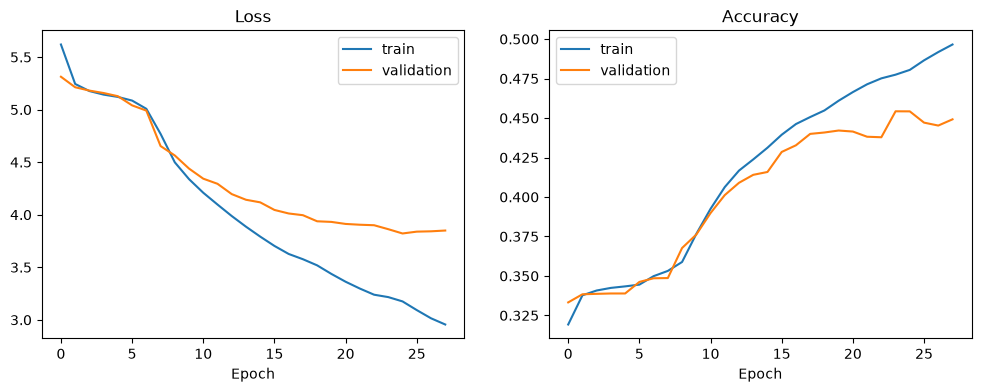

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.show()

#### 6. Evaluate on the test set

In [16]:
loss, acc = model.evaluate(X_test, np.expand_dims(y_test, -1), verbose=0)
print(f"Test loss: {loss:.4f}")
print(f"Test accuracy (all positions incl. padding): {acc:.4f}")

# Accuracy only on real words (ignore padding zeros) – a fairer measure
pred_test = np.argmax(model.predict(X_test, verbose=0), axis=-1)
mask = y_test != 0
word_acc = (pred_test[mask] == y_test[mask]).mean()
print(f"Word-level accuracy (real words only): {word_acc:.4f}")

Test loss: 3.8316
Test accuracy (all positions incl. padding): 0.4473
Word-level accuracy (real words only): 0.2215


#### 7. Translate new sentences

In [17]:
def translate(sentence):
    seq = tok_eng.texts_to_sequences([clean(sentence)])
    seq = pad_sequences(seq, maxlen=eng_len, padding="post")
    pred = np.argmax(model.predict(seq, verbose=0), axis=-1)[0]
    words = [tok_frn.index_word.get(i, "") for i in pred if i != 0]
    return " ".join(words)

# Sentences from the test set (compare with the real translation)
for i in range(min(10, len(X_test))):
    eng = " ".join(tok_eng.index_word[t] for t in X_test[i] if t != 0)
    real = " ".join(tok_frn.index_word[t] for t in y_test[i] if t != 0)
    print(f"EN : {eng}\nREF: {real}\nMT : {translate(eng)}\n")

EN : you're the girl of my dreams
REF: tu es la fille de mes rêves
MT : vous as une la la

EN : we're best friends
REF: nous sommes les meilleurs amis
MT : nous sommes tous de

EN : i often do that for tom
REF: je le fais souvent pour tom
MT : je suis je de de

EN : i was a little disappointed
REF: je fus un peu déçue
MT : j'ai un très

EN : it's all you can really do
REF: c'est tout ce que tu peux vraiment faire
MT : c'est ce ce que que pas

EN : as i was having lunch the phone rang
REF: alors que je déjeunais le téléphone sonna
MT : j'ai que que que de j'ai j'ai

EN : tom always shouts when he is angry
REF: tom hurle toujours lorsqu'il est en colère
MT : tom a besoin de de de

EN : that's just what you needed
REF: c'est précisément ce dont tu avais besoin
MT : c'est ce ce que que que que

EN : he ran through the streets naked
REF: il a couru nu à travers les rues
MT : il a été de son

EN : many young people don't listen to radio anymore
REF: de nombreux jeunes gens n'écoutent plus la

In [18]:
# Short e-commerce style sentences
shop_sentences = [
    "this is a good price",
    "i like this shirt",
    "the shoes are too big",
    "where is my order",
    "thank you for your help",
]
for s in shop_sentences:
    print(f"{s:30s} -> {translate(s)}")

this is a good price           -> c'est un un un
i like this shirt              -> j'aime j'aime de
the shoes are too big          -> les sont sont très
where is my order              -> quelle est est il
thank you for your help        -> merci de votre


#### Notes on the results
- The model learns common short sentences well, but it struggles with long or rare sentences because the whole English sentence is squeezed into **one** context vector.
- Words that never appeared in training are dropped by the tokenizer, so they cannot be translated.
- Plain accuracy is inflated by padding zeros; word-level accuracy on real words is a more honest number.
- Improvements for a real e-commerce system: attention mechanism, teacher forcing with start/end tokens, beam search, sub-word tokenization (BPE), more data, and evaluating with BLEU score – or using a pre-trained Transformer such as MarianMT (`Helsinki-NLP/opus-mt-en-fr`).

---
## What I Learned

- **What Machine Translation is** and its main challenges: ambiguity ("bank"), idioms ("raining cats and dogs"), and low-resource languages.
- **Preprocessing text for neural networks:** cleaning, tokenizing with `Tokenizer` (index 0 is reserved for padding), and padding sequences to a fixed length. I learned that `padding="post"` is better for the output side so real words come first.
- **Encoder–Decoder (Seq2Seq) architecture:** the Embedding layer gives words meaning as vectors, the encoder LSTM compresses the sentence into a context vector, `RepeatVector` passes it to every output step, the decoder LSTM generates a sequence, and `TimeDistributed(Dense + softmax)` picks a word at every position.
- **Training and evaluation:** using `sparse_categorical_crossentropy` with integer targets, splitting into train/validation/test, and using early stopping to avoid overfitting. The tiny 3-sentence example in the lab showed clear overfitting (training accuracy reached about 0.71 while validation accuracy stayed at 0), which taught me that MT needs a lot of data.
- **My Task 2 results:** I trained on 30,000 sentence pairs (up to 8 words). Early stopping ended training at epoch 28 and restored the best weights. The test accuracy was 0.45, but the word-level accuracy on real words was only 0.22. The model translates short and common sentences partly correctly (e.g. "thank you for your help" → "merci de votre", "we're best friends" → "nous sommes tous de"), but it often repeats words (e.g. "c'est un un un") and loses meaning in longer sentences.
- **Reading metrics carefully:** accuracy that includes padding looks better than it really is, so measuring accuracy on real words only gives a truer picture.
- **Limitations of the basic model:** a single context vector loses information in longer sentences, which explains why attention and Transformers are used in modern translation systems like Google Translate.
- **Real-world use:** how a company could use MT to translate product listings and reviews for French-speaking customers.

**Danyal Salman Alhashem – 2240002713**